# Explanation.

Numeric missing values can be filled by 2 methods.
1) Univariate Imputation and
2) Multivariate Imputation.

* Univarriate Imputation means we are filling using the same column.
* Multivariate means we are taking help of other columns as well.

**Methods under Univariate imputation.**

1) Mean/ Median.
2) Arbitrary (Imputing specific number).
3) Random sample imputation.
4) End of Distribution imputation.
5) Automatically select best imputation.

**Methods under Multivariate Imputation.**

1) KNN imputer and
2) Iterative imputer.

# When to use mean and median?
* When the data is normally distributed, use `mean`.
* When the data is skewed, use `median`

# Disadvantages of using mean/ median.
* Changes the distribution of the data.
* Increase in outliers
* Changes in correlation with other columns.

# When to use mean/ median?

* When data is missing at random (MCAR).
* Missing data is < 5%

# In this session, we'll learn `Mean/ median iputation`.

# Steps to be taken after imputation.

1) Check whether there is any change in the distribution of the data or not(There should not be much change).
2) Check the outliers b4 and after(Outliers should not be increased).
3) Check the correlation(Should not change much).

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("00 titanic.csv")

In [3]:
df.sample(10)

,Age,Fare,Family,Survived
412,33.0,90.0000,1,1
243,22.0,7.1250,0,0
421,21.0,7.7333,0,0
55,NaN,35.5000,0,1
226,19.0,10.5000,0,1
449,52.0,30.5000,0,1
173,21.0,7.9250,0,0
356,22.0,55.0000,1,1
807,18.0,7.7750,0,0
611,NaN,7.0500,0,0


In [4]:
df.isnull().sum()

Age         177
Fare         45
Family        0
Survived      0
dtype: int64

In [5]:
# Train/ test split

from sklearn.model_selection import train_test_split

x = df.drop(columns = 'Survived', axis = 'columns')
y = df.drop(x, axis = 'columns')

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [7]:
x_train.shape, x_test.shape

((712, 3), (179, 3))

In [8]:
# Filling with mean and median

age_mean = x_train['Age'].mean()
fare_mean = x_train['Fare'].mean()

age_median = x_train['Age'].median()
fare_median = x_train['Fare'].median()

In [9]:
print(age_mean)
print(age_median)
print(fare_mean)
print(fare_median)

29.32845470692717
28.0
30.76612689450223
14.4542


In [10]:
# Imputation on x_train.
x_train['Age_mean'] = x_train['Age'].fillna(age_mean)
x_train['Age_median'] = x_train['Age'].fillna(age_median)

x_train['Fare_mean'] = x_train['Fare'].fillna(fare_mean)
x_train['Fare_median'] = x_train['Fare'].fillna(fare_median)

# Imputation on x_test.

x_test['Age_mean'] = x_test['Age'].fillna(age_mean)
x_test['Age_median'] = x_test['Age'].fillna(age_median)
x_test['Fare_mean'] = x_test['Fare'].fillna(fare_mean)
x_test['Fare_median'] = x_test['Fare'].fillna(fare_median)

In [11]:
x_train.sample(10)

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
773,NaN,7.2250,0,29.328455,28.0,7.2250,7.2250
626,57.0,12.3500,0,57.000000,57.0,12.3500,12.3500
630,80.0,30.0000,0,80.000000,80.0,30.0000,30.0000
888,NaN,23.4500,3,29.328455,28.0,23.4500,23.4500
470,NaN,7.2500,0,29.328455,28.0,7.2500,7.2500
457,NaN,51.8625,1,29.328455,28.0,51.8625,51.8625
640,20.0,7.8542,0,20.000000,20.0,7.8542,7.8542
215,31.0,113.2750,1,31.000000,31.0,113.2750,113.2750
582,54.0,26.0000,0,54.000000,54.0,26.0000,26.0000
675,18.0,7.7750,0,18.000000,18.0,7.7750,7.7750


In [12]:
print(f"Original Age's variance: {x_train['Age'].var()}")
print(f"Age;s variance after mean imputation: {x_train['Age_mean'].var()}")
print(f"Age's variance after median: {x_train.Age_median.var()}")

print()
print()
print()

print(f"Origianl Fare's variance: {x_train.Fare.var()}")
print(f"Fare's variance after mean: {x_train.Fare_mean.var()}")
print(f"Fare's variance after median: {x_train.Fare_median.var()}")

Original Age's variance: 214.09076753664596
Age;s variance after mean imputation: 169.22505113304504
Age's variance after median: 169.51749234343146



Origianl Fare's variance: 2170.121078813368
Fare's variance after mean: 2051.0849014944915
Fare's variance after median: 2064.880502004094


# Interpretation:

* We can see that the original `variance` of **Age** was `206` which changed to `165` after mean impution. This is a very big change and it is not good. It means mean imputation is not preferable here.
* This drastic change is bcz there were large no.of missing values which we filled with mean. And so, large no.of data points are now around mean.

* Whereas the original `variance` of **Fare** was `2345` which changed to `2220` after mean impution. This is not much big change so we can go for mean imputation on `Fare` column.
* The reason of not much change is there were very less missing value in **Fare** column.

# Comparison through Probability plots

1) Age variable.

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\jugal\AppData\Local\Temp\ipykernel_5072\124427615.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x_train['Age'], shade = True)


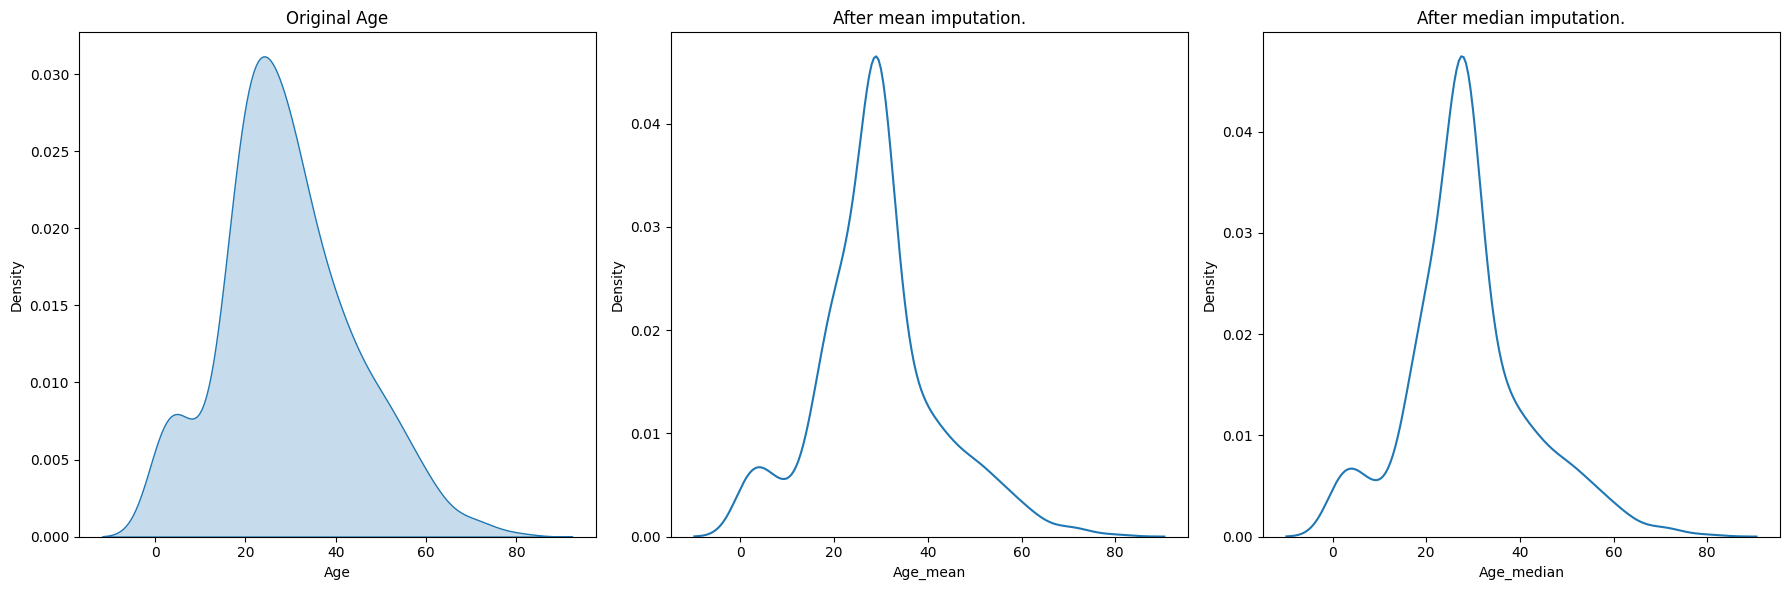

In [14]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
sns.kdeplot(x_train['Age'], shade = True)
plt.title("Original Age")

plt.subplot(132)
sns.kdeplot(x_train['Age_mean'])
plt.title("After mean imputation.")

plt.subplot(133)
sns.kdeplot(x_train.Age_median)
plt.title("After median imputation.")

plt.tight_layout()    # This will fit the charts properly in the screen.

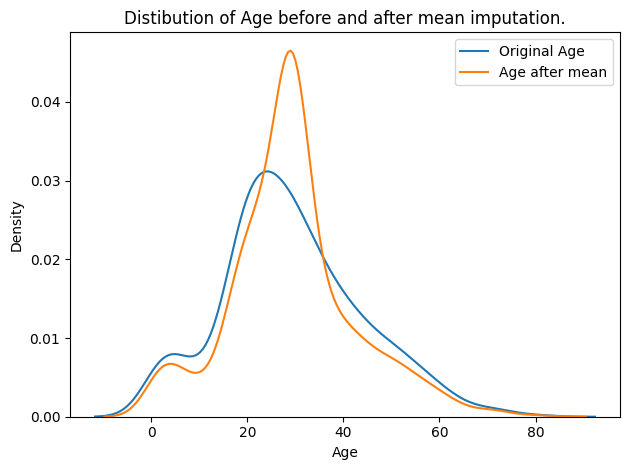

In [15]:
sns.kdeplot(x_train.Age, label = 'Original Age' )
sns.kdeplot(x_train.Age_mean, label = 'Age after mean')
plt.legend()

plt.title("Distibution of Age before and after mean imputation.")
plt.tight_layout()

# Imterpretation of the chart. 
As we discussed earlier, same can be seen in the chart. After mean imputation more values came near mean.

# Now let's see what is the change in Fare column.

In [16]:
print(f"Origianl Fare's variance: {x_train.Fare.var()}")
print(f"Fare's variance after mean: {x_train.Fare_mean.var()}")
print(f"Fare's variance after median: {x_train.Fare_median.var()}")

Origianl Fare's variance: 2170.121078813368
Fare's variance after mean: 2051.0849014944915
Fare's variance after median: 2064.880502004094


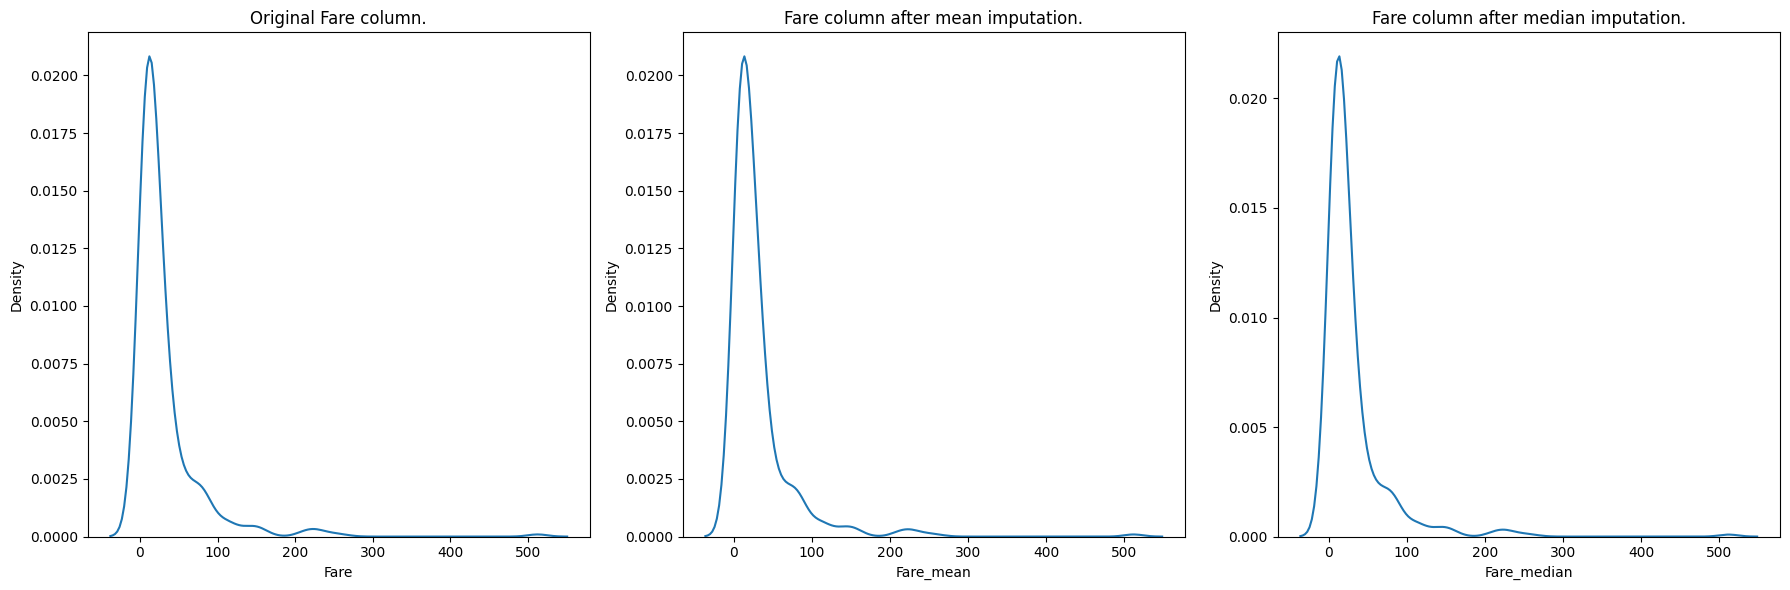

In [17]:
plt.figure(figsize = (18, 6))

plt.subplot(131)
sns.kdeplot(x_train['Fare'])
plt.title("Original Fare column.")

plt.subplot(132)
sns.kdeplot(x_train['Fare_mean'])
plt.title("Fare column after mean imputation.")

plt.subplot(133)
sns.kdeplot(x_train['Fare_median'])
plt.title("Fare column after median imputation.")

plt.tight_layout()

C:\Users\jugal\AppData\Local\Temp\ipykernel_5072\1590903100.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train.Fare, hist = False, label = 'Original Fare')
C:\Users\jugal\AppData\Local\Temp\ipykernel_5072\1590903100.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x

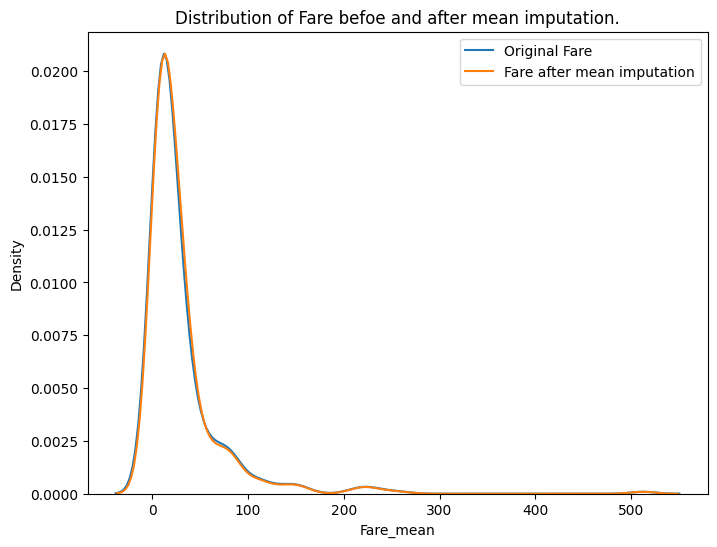

In [18]:
plt.figure(figsize = (8, 6))

sns.distplot(x_train.Fare, hist = False, label = 'Original Fare')
sns.distplot(x_train.Fare_mean, hist = False, label = 'Fare after mean imputation')
plt.title('Distribution of Fare befoe and after mean imputation.')

plt.legend()
# plt.tight_layout()

# Interpretation of the chart: 
* We can see that there's very little to no change in Fare column after mean imputation.
* This is bcz there were very less missing values in Fare columns.

In [19]:
# Let's see what is the correlation b4 and after imputation 

In [20]:
x_train.corr()

,Age,Fare,Family,Age_mean,Age_median,Fare_mean,Fare_median
Age,1.000000,0.092557,-0.349767,1.000000,1.000000,0.090456,0.088283
Fare,0.092557,1.000000,0.175710,0.086571,0.090038,1.000000,1.000000
Family,-0.349767,0.175710,1.000000,-0.283115,-0.281250,0.173614,0.174950
Age_mean,1.000000,0.086571,-0.283115,1.000000,0.999137,0.084824,0.082852
Age_median,1.000000,0.090038,-0.281250,0.999137,1.000000,0.088212,0.086067
Fare_mean,0.090456,1.000000,0.173614,0.084824,0.088212,1.000000,0.996654
Fare_median,0.088283,1.000000,0.174950,0.082852,0.086067,0.996654,1.000000


<AxesSubplot: >

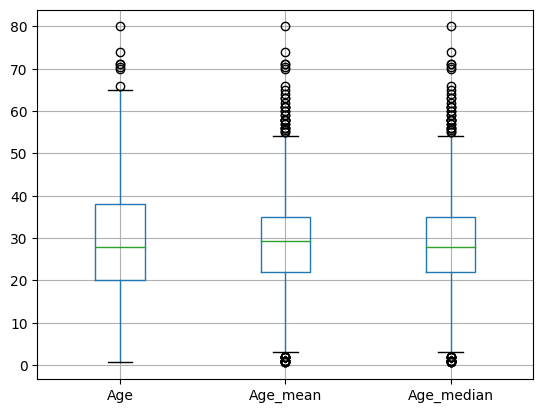

In [21]:
# Box plot

x_train[['Age', 'Age_mean', 'Age_median']].boxplot()


<AxesSubplot: >

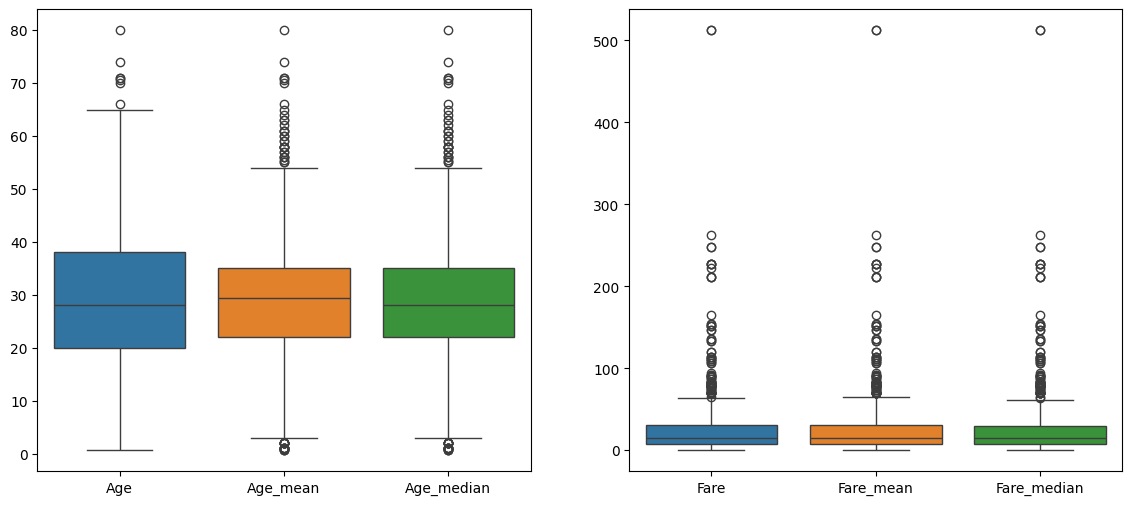

In [22]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.boxplot(x_train[['Age', 'Age_mean', 'Age_median']])

plt.subplot(122)
sns.boxplot(x_train[['Fare', 'Fare_mean', 'Fare_median']])

# plt.tight_layout()

# We can see there's no chamge in outliers in Fare column after imputation. But there is very large change in Age column.
# So, considering all the points till now, we can conclude that we can impute Fare column with mean and median but not Age column.

# Imputatuion through sklearn.

Always use sklearn library for imputation bcz only then we can deal with missing values in the real world, after we deploy the model.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

In [24]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(x, y, test_size = 0.2)

In [25]:
x_train2.sample(5)

,Age,Fare,Family
21,34.0,13.0,0
889,26.0,NaN,0
167,45.0,27.9,5
228,18.0,13.0,0
580,25.0,30.0,2


In [26]:
si_mean = SimpleImputer(strategy = 'mean')
si_median = SimpleImputer(strategy = 'median')

In [27]:
trans = [
    ('Age', si_mean, [0]),
    ('Fare', si_median, [1])
]

In [28]:
ct = ColumnTransformer(transformers = trans, remainder = 'passthrough')

In [29]:
# Applying ColumnTransformer()

x_train2_transformed = ct.fit_transform(x_train2)

x_train2_transformed

array([[33.        ,  8.6625    ,  0.        ],
       [29.78472855, 30.6958    ,  0.        ],
       [18.        , 14.4271    ,  1.        ],
       ...,
       [19.        ,  7.8792    ,  0.        ],
       [21.        ,  7.25      ,  0.        ],
       [29.78472855,  8.05      ,  0.        ]])

In [30]:
print(ct.named_transformers_['Age'].statistics_)
print(ct.named_transformers_['Fare'].statistics_)

# See, we're getting the same mean and median we got earlier.

[29.78472855]
[14.4271]


In [31]:
x_train2_transformed[x_train2_transformed == np.nan]

# We can see there's no missing values after performing imutation through sklearn and ColumnTransformer

array([], dtype=float64)

# Next part: Imputing Arbitrary value.